# SRF heterodyne cavities

In superconducting radio-frequency (SRF) heterodyne experiments, a cavity drives a pump mode whose oscillating magnetic field converts axions into a nearby signal mode. In this tutorial we tune their frequency difference to the axion frequency and calculate mode overlap, scan sensitivity and vibration limits. The SRF modules (`axionfem.srf`, `axionfem.heterodyne`) are beta.


## Mode overlap and size

The overlap amplitude and dimensionless pump frequency are

$$
\eta_{10}=\frac{\left|\int_V\widetilde{\mathbf E}_1^*\cdot\widetilde{\mathbf B}_0\,dV\right|}
{\left(\int_V|\widetilde{\mathbf E}_1|^2\,dV\int_V|\widetilde{\mathbf B}_0|^2\,dV\right)^{1/2}},
\qquad \xi=\frac{\omega_0 V^{1/3}}{c}.
$$

$V$ includes beam-tube stubs, $\omega_0$ is angular pump frequency, $c$ is light speed, and tildes denote mode amplitudes. Both quantities are unchanged by uniform scaling.

We import axionFEM and set up solver helpers for the cavity calculations.


In [1]:
import math, sys, tempfile
from dataclasses import replace
from pathlib import Path

import numpy as np
# Import SciPy's compiled modules before axionFEM: on clusters where a compiler module puts an older libstdc++ on
# LD_LIBRARY_PATH, loading axionFEM's C++ core first would make SciPy's own extensions fail to load.
import scipy.optimize, scipy.integrate                                      # noqa: E401,F401
from scipy.special import jn_zeros, jnp_zeros
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from IPython.display import display  # noqa: F401

try:
    import axionfem as af
except ImportError:                       # running from a source checkout without installing
    sys.path.insert(0, str(Path.cwd().parent / "python"))
    import axionfem as af

from axionfem import srf, heterodyne as het

print("axionFEM", af.__version__)
MU0, C, Z0 = srf.MU0, srf.C_LIGHT, srf.Z0
CELL = srf.PROJECTX_650_B09                       # Project X 650 MHz cell, unshortened [m]
REQ = CELL["equator_radius"]
RUNS = Path(tempfile.mkdtemp(prefix="axf_srf_demo_"))   # solver run directories
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "axes.grid": True, "grid.color": "#e4e3df",
                     "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
                     "lines.linewidth": 1.8, "legend.frameon": False})
# the categorical palette of the other example notebooks
BLUE, ORANGE, GREEN, GOLD, VIOLET, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#6f6e69"


def solve(design, tag, **kw):
    """Solve in RUNS/tag and print the number of unknowns and any solver warning."""
    r = design.solve(RUNS / tag, verbose=0, **kw)
    # the cavity designs carry a nominal 1 T background field (for the form factor C, unused here): drop its warning
    w = [x for x in (r.data.get("warnings") or []) if "background field is present" not in x]
    dofs = r.data.get("mesh", {}).get("dofs")
    print(f"  {tag}: {dofs} DOFs" + (f", warnings: {w}" if w else ""))
    return r


def rel(a, b):
    return a / b - 1.0

axionFEM 0.1.0


## Closed cylinders

We compare axisymmetric solves with analytic results for three degenerate mode pairs.


In [2]:
PAIRS = ("TM020/TE011", "TM030/TE021", "TE012/TM013")
KEYS = [("xi", "xi_pump", "xi"), ("eta_10", "eta_10", "eta_10"), ("B_pk/B0 (pump)", "Bpk_over_B0", "Bpk_over_B0"),
        ("E_pk/(c B0) (pump)", "Epk_over_cB0", "Epk_over_cB0"), ("G pump [ohm]", "G_pump_ohm", "G_pump_ohm"),
        ("G signal [ohm]", "G_signal_ohm", "G_signal_ohm"), ("A/V^(2/3)", "A_over_V23", "A_over_V23")]
cyl = {}
for pair in PAIRS:
    pump, signal = pair.split("/")
    ana = srf.cylinder_pair(pair)
    dc = srf.cylinder_pair_design(pair, 0.10, h=0.10 / 20, order=3, modes=6)
    rc = solve(dc, "cyl_" + pump)
    num = srf.figures_of_merit(rc, pump, signal)
    cyl[pair] = dict(ana=ana, num=num, design=dc, res=rc)

for pair, c in cyl.items():
    ana, num = c["ana"], c["num"]
    f_deg = c["design"].srf_contour["params"]["f_degenerate_Hz"]
    print(f"\n{pair}:  L/R = {ana['L_over_R']:.5f},  "
          f"f = {f_deg / 1e9:.6f} GHz at R = 10 cm;  solver f_pump/f_deg - 1 = {rel(num['f_pump_Hz'], f_deg):+.1e}, "
          f"f_signal/f_deg - 1 = {rel(num['f_signal_Hz'], f_deg):+.1e}")
    print(f"  {'':20s}{'closed form':>13s}{'2D solve':>12s}{'rel. diff':>11s}")
    for lab, kn, ka in KEYS:
        a, n = ana[ka], num[kn]
        d = f"{rel(n, a):+11.1e}" if abs(a) > 1e-9 else f"{'(both 0)':>11s}"
        print(f"  {lab:20s}{a:13.5f}{n:12.5f}{d}")

  cyl_TM020: 17245 DOFs
  cyl_TM030: 16951 DOFs
  cyl_TE012: 24697 DOFs

TM020/TE011:  L/R = 0.79062,  f = 2.633820 GHz at R = 10 cm;  solver f_pump/f_deg - 1 = +3.8e-10, f_signal/f_deg - 1 = +4.4e-10
                        closed form    2D solve  rel. diff
  xi                        7.47569     7.47569   +3.8e-10
  eta_10                    0.43697     0.43702   +9.8e-05
  B_pk/B0 (pump)            1.71004     1.70999   -2.8e-05
  E_pk/(c B0) (pump)        2.93889     2.93890   +4.8e-06
  G pump [ohm]            459.10348   459.10347   -6.8e-09
  G signal [ohm]          580.03894   580.03894   -4.3e-09
  A/V^(2/3)                 6.13439     6.13439   +8.9e-16

TM030/TE021:  L/R = 0.62008,  f = 4.128992 GHz at R = 10 cm;  solver f_pump/f_deg - 1 = +6.8e-09, f_signal/f_deg - 1 = +8.0e-09
                        closed form    2D solve  rel. diff
  xi                       10.80777    10.80777   +6.8e-09
  eta_10                    0.49214     0.49220   +1.2e-04
  B_pk/B0 (pump)     

We compare the closed-form overlaps with `srf.cylinder_pair` and the axisymmetric solves to check agreement.

In [3]:
# Closed-form overlaps; a_n and b_n are zeros of J0 and J1.
a, b = jn_zeros(0, 3), jnp_zeros(0, 2)            # jnp_zeros(0, n) = zeros of J0' = -J1
closed = {"TM020/TE011": 4 * math.sqrt(2) * b[0] / (math.pi * (a[1] ** 2 - b[0] ** 2)),
          "TM030/TE021": 4 * math.sqrt(2) * b[1] / (math.pi * (a[2] ** 2 - b[1] ** 2)),
          "TE012/TM013": 16 * b[0] / (5 * math.pi * (b[0] ** 2 - a[0] ** 2))}
for pair, eta in closed.items():
    print(f"{pair}: eta_10 closed form {eta:.8f}, srf.cylinder_pair {cyl[pair]['ana']['eta_10']:.8f}, "
          f"2D solve {cyl[pair]['num']['eta_10']:.8f}")

TM020/TE011: eta_10 closed form 0.43697304, srf.cylinder_pair 0.43697304, 2D solve 0.43701608
TM030/TE021: eta_10 closed form 0.49213898, srf.cylinder_pair 0.49213898, 2D solve 0.49219741
TE012/TM013: eta_10 closed form 0.43859289, srf.cylinder_pair 0.43859289, 2D solve 0.43860585


## Elliptical cell

We compare the original Project X contour with a shortened contour chosen to bring TM020 and TE011 together.


unshortened  V = 19.585 L (tubes included), A = 0.4317 m^2, length 407.6 mm, wall angle 5.25 deg, 345 wall vertices
x 0.86       V = 17.063 L (tubes included), A = 0.4097 m^2, length 378.5 mm, wall angle 4.52 deg, 331 wall vertices
tangent points (z, r) [mm] of the x 0.86 cell: [(-74.07, 80.76), (-70.64, 124.13)]


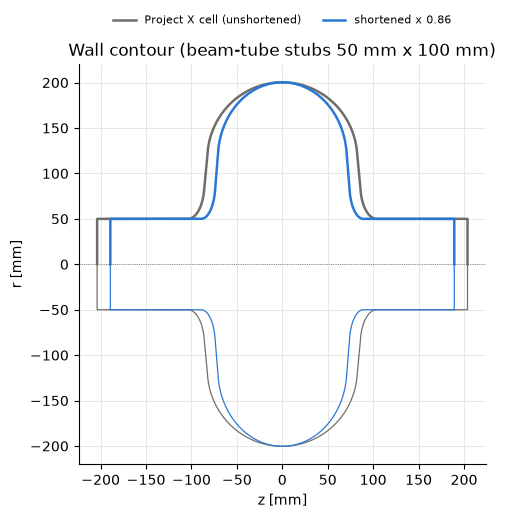

In [4]:
con0 = srf.elliptical_cell_contour(CELL, axial_factor=1.0)
con = srf.elliptical_cell_contour(CELL, axial_factor=0.86)
for name, c in (("unshortened", con0), ("x 0.86", con)):
    p = c["params"]
    print(f"{name:12s} V = {c['V_m3'] * 1e3:6.3f} L (tubes included), A = {c['A_m2']:.4f} m^2, length {c['length'] * 1e3:.1f} mm, "
          f"wall angle {c['tangent_angle_deg']:.2f} deg, {len(c['wall'])} wall vertices")
print("tangent points (z, r) [mm] of the x 0.86 cell:", [tuple(round(1e3 * v, 2) for v in q) for q in con["params"]["tangent_points_zr"]])

fig, ax = plt.subplots(figsize=(7.5, 5.2))
for c, col, lab in ((con0, GREY, "Project X cell (unshortened)"), (con, BLUE, "shortened x 0.86")):
    W = np.array(c["wall"])
    ax.plot(W[:, 1] * 1e3, W[:, 0] * 1e3, color=col, label=lab)
    ax.plot(W[:, 1] * 1e3, -W[:, 0] * 1e3, color=col, lw=0.9)
ax.axhline(0, color=GREY, lw=0.6, ls=":")
ax.set_aspect("equal"); ax.set_xlabel("z [mm]"); ax.set_ylabel("r [mm]")
ax.set_title("Wall contour (beam-tube stubs 50 mm x 100 mm)"); ax.legend(loc="lower center", fontsize=8,
                                                                      bbox_to_anchor=(0.5, 1.07), ncol=2)
plt.show()

### Tuning the splitting

We sweep the axial factor to locate the frequency crossing.


tuner: axial factor 0.86002, f = 1.41651 GHz (7 solves)
d[(f_TE011 - f_TM020)/f]/ds = -0.570 per unit axial factor: a 1 % change of the splitting needs ds = 0.0175


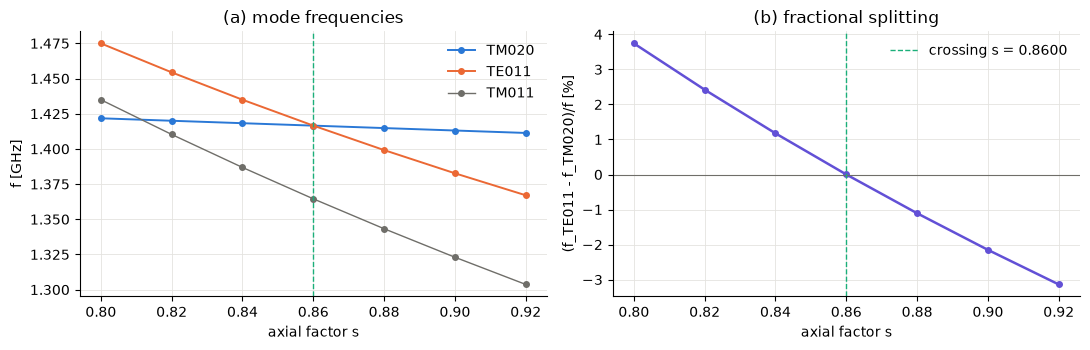

In [5]:
COARSE = {"h": REQ / 20, "order": 2, "modes": 6}
sweep = []
for s in np.round(np.arange(0.80, 0.921, 0.02), 3):
    d = srf.elliptical_cell_design(CELL, axial_factor=float(s), **COARSE)
    r = d.solve(RUNS / f"sweep_{s}", verbose=0)
    lab = srf.classify_modes(r, d.srf_contour)
    row = {"s": float(s)}
    for nm in ("TM020", "TE011", "TM011"):
        hit = [m for m in lab if m["name"] == nm]
        row[nm] = hit[0]["f_Hz"] if len(hit) == 1 else np.nan
    sweep.append(row)
tune = srf.tune_degeneracy("TM020", "TE011", cell=CELL, bracket=(0.84, 0.88), tol=2e-5, design_kw=COARSE,
                           workdir=str(RUNS / "tuner"))
print(f"tuner: axial factor {tune['axial_factor']:.5f}, f = {tune['f_Hz'] / 1e9:.5f} GHz "
      f"({len(tune['history'])} solves)")
# slope of the fractional splitting at the crossing: linear fit through the sweep points 0.84, 0.86, 0.88
near = [x for x in sweep if 0.835 < x["s"] < 0.885]
slope = np.polyfit([x["s"] for x in near], [(x["TE011"] - x["TM020"]) / x["TM020"] for x in near], 1)[0]
print(f"d[(f_TE011 - f_TM020)/f]/ds = {slope:.3f} per unit axial factor: a 1 % change of the splitting needs "
      f"ds = {0.01 / abs(slope):.4f}")

S = np.array([x["s"] for x in sweep])
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 3.6))
for nm, col in (("TM020", BLUE), ("TE011", ORANGE), ("TM011", GREY)):
    ax0.plot(S, [x[nm] / 1e9 for x in sweep], "o-", color=col, ms=4, label=nm, lw=1.4 if nm != "TM011" else 1.0)
ax0.axvline(tune["axial_factor"], color=GREEN, lw=1, ls="--")
ax0.set_xlabel("axial factor s"); ax0.set_ylabel("f [GHz]"); ax0.legend(); ax0.set_title("(a) mode frequencies")
split = np.array([(x["TE011"] - x["TM020"]) / x["TM020"] for x in sweep])
ax1.plot(S, 100 * split, "o-", color=VIOLET, ms=4)
ax1.axhline(0, color=GREY, lw=0.8); ax1.axvline(tune["axial_factor"], color=GREEN, lw=1, ls="--",
                                                 label=f"crossing s = {tune['axial_factor']:.4f}")
ax1.set_xlabel("axial factor s"); ax1.set_ylabel("(f_TE011 - f_TM020)/f [%]"); ax1.legend()
ax1.set_title("(b) fractional splitting")
fig.tight_layout(); plt.show()

The slope estimates the deformation needed to scan; no mechanical tuner is modeled.


### Mode solve

We solve the modes to inspect their labels, frequencies and residuals.


In [6]:
dcell = srf.elliptical_cell_design(CELL, axial_factor=0.86, h=REQ / 40, order=3, modes=6)
rcell = solve(dcell, "cell_n40_o3")
labels = srf.classify_modes(rcell, dcell.srf_contour)
print(f"{'mode':7s}{'f [GHz]':>11s}{'G [ohm]':>10s}{'residual':>11s}")
for m in labels:
    print(f"{m['name']:7s}{m['f_Hz'] / 1e9:11.6f}{m['G_ohm']:10.2f}{m['residual_true']:11.1e}")

  cell_n40_o3: 105238 DOFs
mode       f [GHz]   G [ohm]   residual
TM010     0.649550    231.40    7.1e-11
TM011     1.364506    350.93    2.3e-12
TM020     1.416510    524.47    1.2e-12
TE011     1.416531    604.48    7.0e-13
TM021     1.942838    519.52    2.8e-12
TE021     2.027390   1138.99    1.0e-11
TM030     2.094487    631.09    5.6e-12
TE012     2.276414    803.33    3.1e-12
TM012     2.285543    607.62    1.2e-11
TE031     2.702482   1688.04    1.9e-11
TE022     2.731251   1157.60    3.7e-12
TE013     3.139762   1082.10    1.2e-12


### Geometry factors

`srf.figures_of_merit` returns overlap, frequencies (Hz) and geometry factors (ohms).

We compute these quantities and field peaks to characterize the mode pair.


In [7]:
fom = srf.figures_of_merit(rcell, "TM020", "TE011")
rows = [("f TM020 [GHz]", "f_pump_Hz", 1e-9), ("f TE011 [GHz]", "f_signal_Hz", 1e-9), ("V [L]", "V_m3", 1e3),
        ("xi", "xi_pump", 1), ("eta_10", "eta_10", 1), ("B_pk/B0 (wall max)", "Bpk_over_B0", 1),
        ("B/B0 at the equator", "B_equator_over_B0", 1), ("E_pk/(c B0)", "Epk_over_cB0", 1),
        ("A/V^(2/3)", "A_over_V23", 1), ("G pump [ohm]", "G_pump_ohm", 1), ("G signal [ohm]", "G_signal_ohm", 1)]
print(f"{'quantity':22s}{'value':>13s}")
for lab, k, u in rows:
    print(f"{lab:22s}{fom[k] * u:13.6g}")
print(f"\nsplitting f_TE011 - f_TM020 = {fom['splitting_Hz'] / 1e3:.1f} kHz ({fom['splitting_Hz'] / fom['f_pump_Hz']:.1e} of f)")
print(f"eta_10^2 = {fom['eta_10_squared']:.4f}")
print("B_pk at (r, z) =", tuple(round(1e3 * v, 1) for v in fom["pump_peaks"]["Bpk_at_rz"]), "mm;  E_pk at (r, z) =",
      tuple(round(1e3 * v, 1) for v in fom["pump_peaks"]["Epk_at_rz"]), "mm")
print("checks:", {k: (round(v, 6) if isinstance(v, float) else v) for k, v in fom["checks"].items()})

quantity                      value
f TM020 [GHz]               1.41651
f TE011 [GHz]               1.41653
V [L]                       17.0628
xi                          7.64298
eta_10                     0.449217
B_pk/B0 (wall max)            1.464
B/B0 at the equator         1.40394
E_pk/(c B0)                 1.84516
A/V^(2/3)                   6.18223
G pump [ohm]                524.474
G signal [ohm]              604.478

splitting f_TE011 - f_TM020 = 20.3 kHz (1.4e-05 of f)
eta_10^2 = 0.2018
B_pk at (r, z) = (77.7, -74.4) mm;  E_pk at (r, z) = (52.8, -83.5) mm
checks: {'int_E1^2 (1 expected)': 0.999859, 'int_E0^2 (1 expected)': 0.999881, 'c^2 int B0^2 (1 expected at resonance)': 0.999881, 'c^2 int B1^2 (1 expected)': 0.999883, 'n_wall_points': 2905, 'subdiv': 4, 'volume_contour_vs_solver': -0.0}


We use the wall maximum for $B_{\rm pk}$; the equator is a diagnostic. $B_0$ is spatial rms, peak in time. The wall contour and mesh should be refined for peak fields, especially electric peaks, normalized by $cB_0$.


### Meridional fields

Opposite signs of the overlap density cancel in the volume integral.

We plot the mode fields and compare cell and cylinder overlap densities to show these cancellations.


volume average of the overlap density: 0.44907  (eta_10 = 0.44922)


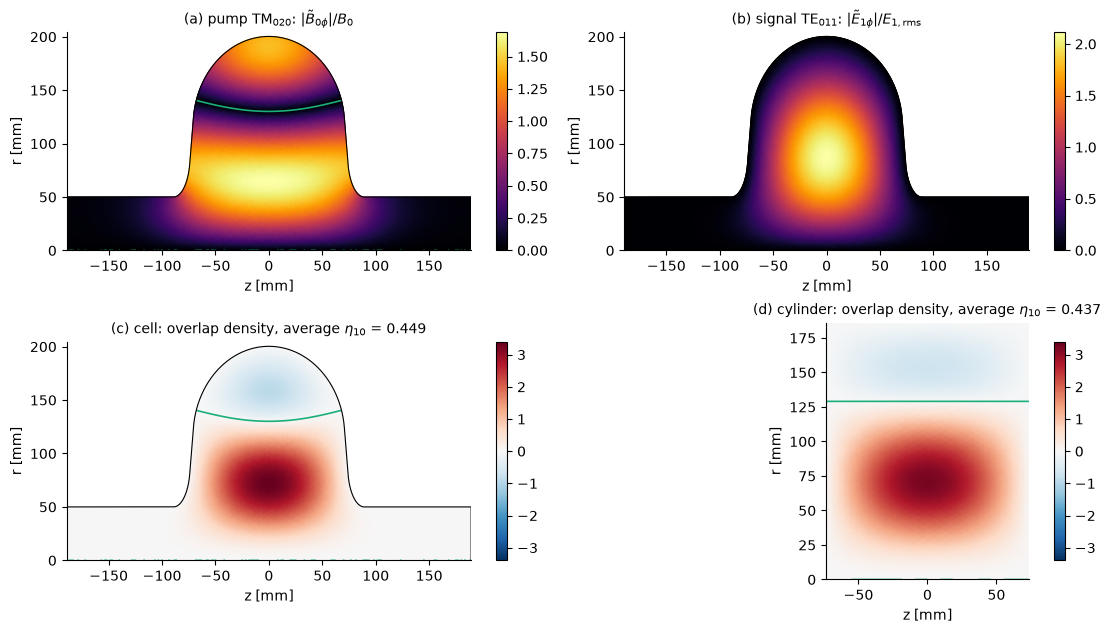

In [8]:
pr, sg = srf.find_mode(rcell, "TM020", labels=labels), srf.find_mode(rcell, "TE011", labels=labels)
Fp, Fs = rcell.cavity_mode_field(pr, subdiv=2), rcell.cavity_mode_field(sg, subdiv=2)
V = fom["V_m3"]
B0rms = fom["pump_peaks"]["B_rms"]
E1rms = math.sqrt(fom["checks"]["int_E1^2 (1 expected)"] / V)
Bphi, Ephi = MU0 * Fp["H_phi"] / B0rms, Fs["E_phi"] / E1rms
ov = Bphi * Ephi
sgn = np.sign(srf._tri_product_integral(Fp["r"], Fp["z"], Fp["tris"], Bphi, Ephi))
print(f"volume average of the overlap density: {sgn * srf._tri_product_integral(Fp['r'], Fp['z'], Fp['tris'], Bphi, Ephi) / V:.5f}"
      f"  (eta_10 = {fom['eta_10']:.5f})")
ov = sgn * ov

ccyl = cyl["TM020/TE011"]
rc = ccyl["res"]; lc = srf.classify_modes(rc, ccyl["design"].srf_contour)
pc, sc_ = srf.find_mode(rc, "TM020", labels=lc), srf.find_mode(rc, "TE011", labels=lc)
Gp, Gs = rc.cavity_mode_field(pc, subdiv=2), rc.cavity_mode_field(sc_, subdiv=2)
Vc = ccyl["num"]["V_m3"]
Bc = MU0 * Gp["H_phi"] / ccyl["num"]["pump_peaks"]["B_rms"]
Ec = Gs["E_phi"] / math.sqrt(ccyl["num"]["checks"]["int_E1^2 (1 expected)"] / Vc)
ovc = Bc * Ec * np.sign(srf._tri_product_integral(Gp["r"], Gp["z"], Gp["tris"], Bc, Ec))
kscale = ccyl["num"]["f_pump_Hz"] / fom["f_pump_Hz"]          # cylinder lengths x this -> same frequency as the cell

Wc = np.array(dcell.srf_contour["wall"])
fig, axs = plt.subplots(2, 2, figsize=(11.5, 6.4))
panels = [(axs[0, 0], Fp, np.abs(Bphi), "inferno", r"(a) pump TM$_{020}$: $|\tilde B_{0\phi}|/B_0$", 1.0),
          (axs[0, 1], Fs, np.abs(Ephi), "inferno", r"(b) signal TE$_{011}$: $|\tilde E_{1\phi}|/E_{1,\rm rms}$", 1.0),
          (axs[1, 0], Fp, ov, "RdBu_r", r"(c) cell: overlap density, average $\eta_{10}$" + f" = {fom['eta_10']:.3f}", 1.0),
          (axs[1, 1], Gp, ovc, "RdBu_r", r"(d) cylinder: overlap density, average $\eta_{10}$" + f" = {ccyl['num']['eta_10']:.3f}",
           kscale)]
lim = max(np.abs(ov).max(), np.abs(ovc).max())
ze, rmax = dcell.srf_contour["z_end"] * 1e3, REQ * 1e3
for ax, F, val, cmap, title, s in panels:
    kw = dict(norm=TwoSlopeNorm(0, -lim, lim)) if cmap == "RdBu_r" else {}
    im = ax.tripcolor(F["z"] * s * 1e3, F["r"] * s * 1e3, F["tris"], val, cmap=cmap, shading="gouraud", rasterized=True, **kw)
    fig.colorbar(im, ax=ax, shrink=0.85)
    ax.set_title(title, fontsize=10); ax.set_aspect("equal"); ax.grid(False)
    if F is Fp or F is Fs:
        ax.set_xlim(-ze, ze); ax.set_ylim(0, rmax * 1.02)
    ax.set_xlabel("z [mm]"); ax.set_ylabel("r [mm]")
for ax, F, B in ((axs[0, 0], Fp, Bphi), (axs[1, 0], Fp, Bphi), (axs[1, 1], Gp, Bc)):
    s = kscale if F is Gp else 1.0
    ax.tricontour(F["z"] * s * 1e3, F["r"] * s * 1e3, F["tris"], B, levels=[0.0], colors=GREEN, linewidths=1.2)
for ax in axs[0, 0], axs[0, 1], axs[1, 0]:
    ax.plot(Wc[:, 1] * 1e3, Wc[:, 0] * 1e3, color="k", lw=0.8)
fig.tight_layout(); plt.show()

### Equator fields

The green circle marks the pump field's sign reversal.

We plot the equator fields and overlap density to show their radial structure.


pump sign-reversal radius at z = 0: r = 130.1 mm = 0.650 R_eq


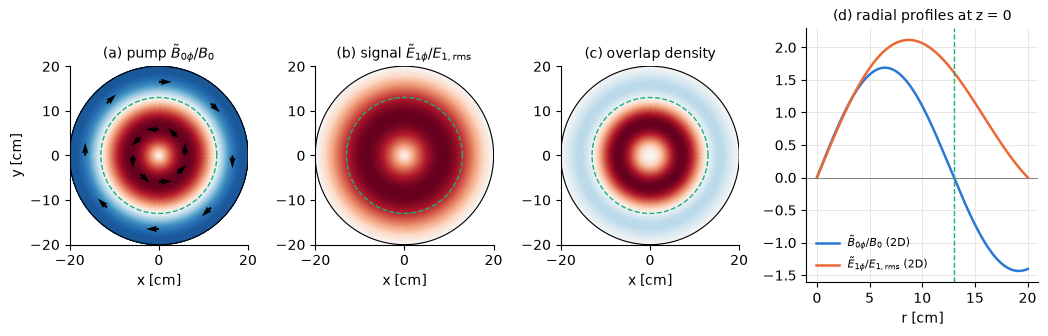

In [9]:
rr = np.linspace(1e-6, 1 - 1e-6, 801) * REQ
lp, ls = rcell.cavity_mode_sample(pr, rr, 0 * rr), rcell.cavity_mode_sample(sg, rr, 0 * rr)
Bl, El = MU0 * lp["H_phi"] / B0rms, sgn * ls["E_phi"] / E1rms
i0 = np.nonzero(np.diff(np.sign(Bl)))[0][0]
r_node = float(np.interp(0.0, [Bl[i0 + 1], Bl[i0]], [rr[i0 + 1], rr[i0]]))
print(f"pump sign-reversal radius at z = 0: r = {r_node * 1e3:.1f} mm = {r_node / REQ:.3f} R_eq")

R, T = np.meshgrid(rr, np.linspace(0, 2 * np.pi, 241))
X, Y = R * np.cos(T), R * np.sin(T)
fig = plt.figure(figsize=(12.5, 3.3))
gs = fig.add_gridspec(1, 4, width_ratios=[1, 1, 1, 1.3], wspace=0.35)
th = np.linspace(0, 2 * np.pi, 300)
for k, (prof, title) in enumerate(((Bl, r"(a) pump $\tilde B_{0\phi}/B_0$"), (El, r"(b) signal $\tilde E_{1\phi}/E_{1,\rm rms}$"),
                                   (Bl * El, r"(c) overlap density"))):
    ax = fig.add_subplot(gs[0, k])
    F = np.interp(R, rr, prof)
    m = np.abs(F).max()
    ax.pcolormesh(X * 100, Y * 100, F, cmap="RdBu_r", norm=TwoSlopeNorm(0, -m, m), shading="gouraud", rasterized=True)
    ax.plot(REQ * 100 * np.cos(th), REQ * 100 * np.sin(th), color="k", lw=0.8)
    ax.plot(r_node * 100 * np.cos(th), r_node * 100 * np.sin(th), color=GREEN, lw=1.0, ls="--")
    if k == 0:                                   # circulation arrows of the pump field
        for rq in (0.45 * r_node, 0.5 * (r_node + REQ)):
            for t in np.linspace(0, 2 * np.pi, 8, endpoint=False):
                v = float(np.interp(rq, rr, Bl))
                ax.quiver(rq * 100 * np.cos(t), rq * 100 * np.sin(t), -np.sin(t) * np.sign(v), np.cos(t) * np.sign(v),
                          scale=14, width=0.012, color="k")
    ax.set_aspect("equal"); ax.set_title(title, fontsize=10); ax.grid(False); ax.set_xlabel("x [cm]")
    if k == 0:
        ax.set_ylabel("y [cm]")
ax = fig.add_subplot(gs[0, 3])
ax.plot(rr * 100, Bl, color=BLUE, label=r"$\tilde B_{0\phi}/B_0$ (2D)")
ax.plot(rr * 100, El, color=ORANGE, label=r"$\tilde E_{1\phi}/E_{1,\rm rms}$ (2D)")
ax.axhline(0, color=GREY, lw=0.6); ax.axvline(r_node * 100, color=GREEN, lw=1, ls="--")
ax.set_xlabel("r [cm]"); ax.set_title("(d) radial profiles at z = 0", fontsize=10); ax.legend(fontsize=8)
plt.show()

### Wall fields

We plot the wall fields to locate their maxima.


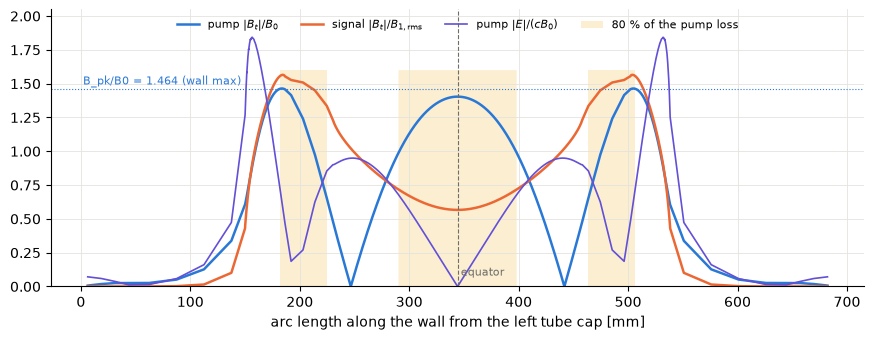

sampled wall max of the pump |B_t|/B0 = 1.4641 (lattice value 1.4640), at the equator 1.4041


In [10]:
def wall_profile(res, row, wall, n_per_seg=4, eps=1e-4 * REQ):
    """Arc length s, (r, z), |B_t| and |E| a distance eps inside the wall polyline (both normals tried; the one inside
    the cavity returns finite values). eps is large enough for every point to be located in the curved mesh."""
    W = np.asarray(wall, float)
    P, Tn, S, s0 = [], [], [], 0.0
    for p0, p1 in zip(W[:-1], W[1:]):
        L = float(np.hypot(*(p1 - p0)))
        if L == 0:
            continue
        for u in (np.arange(n_per_seg) + 0.5) / n_per_seg:
            P.append(p0 + u * (p1 - p0)); Tn.append((p1 - p0) / L); S.append(s0 + u * L)
        s0 += L
    P, Tn, S = np.array(P), np.array(Tn), np.array(S)
    N = np.column_stack([-Tn[:, 1], Tn[:, 0]])
    best = max((res.cavity_mode_sample(row, *(P + sg * eps * N).T) for sg in (1, -1)),
               key=lambda d: np.isfinite(d["H_phi"]).mean())
    Bt = MU0 * np.sqrt(best["H_phi"] ** 2 + (best["H_r"] * Tn[:, 0] + best["H_z"] * Tn[:, 1]) ** 2)
    E = np.sqrt(best["E_r"] ** 2 + best["E_phi"] ** 2 + best["E_z"] ** 2)
    return S, P, np.nan_to_num(Bt), np.nan_to_num(E)   # points on the axis (cap ends) may fall outside: 0

wall = dcell.srf_contour["wall"]
s_w, P_w, Bt_p, E_p = wall_profile(rcell, pr, wall)
_, _, Bt_s, _ = wall_profile(rcell, sg, wall)
B1rms = fom["signal_peaks"]["B_rms"]
seg = np.linalg.norm(np.diff(np.asarray(wall, float), axis=0), axis=1)
ds = np.repeat(seg[seg > 0] / 4, 4)          # arc length per sample (4 samples per segment)
loss = P_w[:, 0] * Bt_p ** 2 * ds
order = np.argsort(loss)[::-1]
frac = np.cumsum(loss[order]) / loss.sum()
in80 = np.zeros(len(loss), bool); in80[order[: np.searchsorted(frac, 0.8) + 1]] = True
s_eq = s_w[np.argmax(P_w[:, 0])]
fig, ax = plt.subplots(figsize=(10.5, 3.6))
ax.plot(s_w * 1e3, Bt_p / B0rms, color=BLUE, label=r"pump $|B_t|/B_0$")
ax.plot(s_w * 1e3, Bt_s / B1rms, color=ORANGE, label=r"signal $|B_t|/B_{1,\rm rms}$")
ax.plot(s_w * 1e3, E_p / (C * B0rms), color=VIOLET, lw=1.2, label=r"pump $|E|/(cB_0)$")
ax.fill_between(s_w * 1e3, 0, 1.6, where=in80, color=GOLD, alpha=0.18, lw=0, label="80 % of the pump loss")
ax.axhline(fom["Bpk_over_B0"], color=BLUE, lw=0.8, ls=":")
ax.axvline(s_eq * 1e3, color=GREY, lw=0.8, ls="--")
ax.text(s_eq * 1e3 + 3, 0.08, "equator", color=GREY, fontsize=8)
ax.text(2, fom["Bpk_over_B0"] + 0.03, f"B_pk/B0 = {fom['Bpk_over_B0']:.3f} (wall max)", color=BLUE, fontsize=8)
ax.set_xlabel("arc length along the wall from the left tube cap [mm]"); ax.set_ylim(0, 2.05)
ax.legend(fontsize=8, ncol=4, loc="upper center")
plt.show()
print(f"sampled wall max of the pump |B_t|/B0 = {Bt_p.max() / B0rms:.4f} (lattice value {fom['Bpk_over_B0']:.4f}), "
      f"at the equator {Bt_p[np.argmax(P_w[:, 0])] / B0rms:.4f}")

### Comparison with 3D

We revolve the contour into a cavity to compare 3D and axisymmetric results; this cell needs a build with the 3D engine and STRUMPACK (the 3D shift-invert eigensolver) and runs on four MPI ranks.


  cell_3d_n8_o2: 350852 DOFs, warnings: ['3D eigenmodes: 1 mode(s) within 1e-4 (in k^2) of a returned mode lie just outside the returned window: a near-degenerate pair is cut by the window edge; request more modes to get both members']
3D: 53406 elements; E_phi fraction pump / signal = 4.0e-04 / 0.999538
                  2D (R/40, o3)  3D (R/8, o2)  rel. diff
f TM020 [GHz]          1.416510      1.416585   +5.2e-05
f TE011 [GHz]          1.416531      1.416612   +5.8e-05
xi                     7.642981      7.643365   +5.0e-05
eta_10                 0.449217      0.448883   -7.4e-04
G pump [ohm]         524.474030    524.147070   -6.2e-04
G signal [ohm]       604.478497    603.895223   -9.6e-04
B_pk/B0                1.464004      1.487265   +1.6e-02
E_pk/(c B0)            1.845159      1.783570   -3.3e-02
eta_10 (signal E, pump B) = 0.44888, eta_01 (pump E, signal B) = 0.44887
z = 0 profiles, 3D vs 2D: max |diff| = 0.065 (pump B/B0), 0.026 (signal E/E_rms)


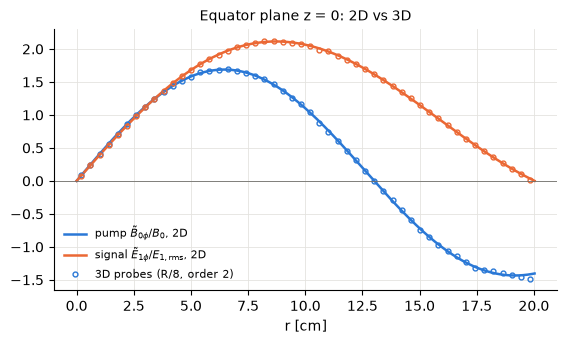

In [11]:
NR = 4                                       # MPI ranks of the 3D solve
RUN_3D = af.build_info()["engine_3d"] and af.build_info()["strumpack"]
if RUN_3D:
    xs = np.linspace(0.01, 0.99, 50) * REQ
    d3 = srf.elliptical_cell_design_3d(CELL, axial_factor=0.86, h=REQ / 8, order=2, modes=16,
                                       target_f_Hz=0.5 * (fom["f_pump_Hz"] + fom["f_signal_Hz"]))
    d3.doc["fullwave"]["field_probes"] = [[float(x), 0.0, 0.0] for x in xs]
    r3 = solve(d3, "cell_3d_n8_o2", mpi_ranks=NR)
    f3 = srf.figures_of_merit_3d(r3, fom["f_pump_Hz"], fom["f_signal_Hz"], contour=d3.srf_contour)
    print(f"3D: {r3.data['mesh'].get('elements')} elements; E_phi fraction pump / signal = "
          f"{f3['E_azimuthal_fraction'][0]:.1e} / {f3['E_azimuthal_fraction'][1]:.6f}")
    print(f"{'':16s}{'2D (R/40, o3)':>15s}{'3D (R/8, o2)':>14s}{'rel. diff':>11s}")
    for lab, k in (("f TM020 [GHz]", "f_pump_Hz"), ("f TE011 [GHz]", "f_signal_Hz"), ("xi", "xi_pump"),
                   ("eta_10", "eta_10"), ("G pump [ohm]", "G_pump_ohm"), ("G signal [ohm]", "G_signal_ohm"),
                   ("B_pk/B0", "Bpk_over_B0"), ("E_pk/(c B0)", "Epk_over_cB0")):
        u = 1e-9 if k.startswith("f_") else 1
        print(f"{lab:16s}{fom[k] * u:15.6f}{f3[k] * u:14.6f}{rel(f3[k], fom[k]):+11.1e}")
    print(f"eta_10 (signal E, pump B) = {f3['eta_10']:.5f}, eta_01 (pump E, signal B) = {f3['eta_01_transpose']:.5f}")
    modes3 = r3.fullwave["eigenmodes"]["modes"]
    mp3, ms3 = modes3[f3["i_pump"]], modes3[f3["i_signal"]]
    B3 = np.array(mp3["probes"]["B"])[:, 1] / mp3["peak_wall_fields"]["B_rms"]           # B_y = B_phi on the +x axis
    E3 = np.array(ms3["probes"]["E"])[:, 1] * math.sqrt(r3.fullwave["cavity"]["volume_m3"])  # int |E|^2 = 1
    B3 *= np.sign(np.dot(B3, np.interp(xs, rr, Bl))); E3 *= np.sign(np.dot(E3, np.interp(xs, rr, El)))
    print(f"z = 0 profiles, 3D vs 2D: max |diff| = {np.abs(B3 - np.interp(xs, rr, Bl)).max():.3f} (pump B/B0), "
          f"{np.abs(E3 - np.interp(xs, rr, El)).max():.3f} (signal E/E_rms)")
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    ax.plot(rr * 100, Bl, color=BLUE, label=r"pump $\tilde B_{0\phi}/B_0$, 2D")
    ax.plot(rr * 100, El, color=ORANGE, label=r"signal $\tilde E_{1\phi}/E_{1,\rm rms}$, 2D")
    ax.plot(xs * 100, B3, "o", color=BLUE, ms=3.5, mfc="none", label="3D probes (R/8, order 2)")
    ax.plot(xs * 100, E3, "o", color=ORANGE, ms=3.5, mfc="none")
    ax.axhline(0, color=GREY, lw=0.6); ax.set_xlabel("r [cm]"); ax.set_title("Equator plane z = 0: 2D vs 3D", fontsize=10)
    ax.legend(fontsize=8); plt.show()
else:
    print("3D cross-check skipped: this build has no 3D engine with STRUMPACK")

The 3D surface mesh should be refined before using its wall peaks or losses. When the eigensolver warns that a returned mode has a near-degenerate partner just outside the requested window, requesting more modes (`modes=` of `elliptical_cell_design_3d`) returns both members. The pump and signal are the returned modes with the required field pattern (azimuthal-E fraction below 0.01 or above 0.99) closest to the axisymmetric frequencies at the centre of the window, so a mode outside the window does not change them.


## Sensitivity

`het.SRFGeometry.from_modes` passes mode properties to the scan model. On resonance, for an axion line narrower than the signal linewidth,

$$
P_{\rm sig}=\frac14 g^2\eta^2 B_0^2\rho V\frac{Q_1}{\omega_1}.
$$

This uses natural Heaviside–Lorentz units: $g$ is axion–photon coupling, $\rho$ axion density, $\eta$ the overlap above, and $Q_1$ the loaded signal quality factor at angular frequency $\omega_1$. Python uses SI, with coupling in GeV$^{-1}$ and density in GeV/cm$^3$.

We compare geometry parameters from the solved modes with the preset to check the scan inputs.


In [12]:
geos = {"this solve, B_pk wall": het.SRFGeometry.from_modes(fom, bpk="wall", name="notebook, wall"),
        "equator (diagnostic)": het.SRFGeometry.from_modes(fom, bpk="equator", name="notebook, equator diagnostic"),
        "preset PROJECTX_086": het.PROJECTX_086}
print(f"{'':27s}{'xi':>8s}{'eta':>8s}{'G0':>8s}{'G1':>8s}{'Bpk/B0':>8s}{'A/V^2/3':>9s}{'Epk/cB0':>9s}")
for k, g in geos.items():
    print(f"{k:27s}{g.xi:8.4f}{g.eta:8.4f}{g.G_pump_ohm:8.2f}{g.G_signal_ohm:8.2f}{g.Bpk_over_B0:8.4f}{g.area_coeff:9.4f}"
          f"{g.Epk_over_cB0:9.4f}")

                                 xi     eta      G0      G1  Bpk/B0  A/V^2/3  Epk/cB0
this solve, B_pk wall        7.6430  0.4492  524.47  604.48  1.4640   6.1822   1.8452
equator (diagnostic)         7.6430  0.4492  524.47  604.48  1.4039   6.1822   1.8452
preset PROJECTX_086          7.6430  0.4492  524.47  604.48  1.4640   6.1822   1.8431


### Required volume

`het.design_A` sizes a scenario (`het.ScenarioA`: surface resistance, peak wall field, flat receiver noise and wall temperature) for a band and live time (`het.Target`). The scenario and band below are round, illustrative numbers, not a proposed experiment: DFSZ over 0.2–2 MHz in one year. `A` is flat receiver noise in quanta; temperature sets wall noise.

We compare required volumes using the wall maximum and equator field.


In [13]:
SCEN = {"illustrative": het.ScenarioA("illustrative", Rs_ohm=10e-9, Bpk_T=0.10, A=2.0, T_K=2.0)}
band = het.Target(f_min_Hz=0.2e6, f_max_Hz=2.0e6, live_time_yr=1.0)        # an illustrative band and live time
designs = {}
for sname, sc in SCEN.items():
    print(f"\n{sname}: R_s = {sc.Rs_ohm * 1e9:g} nOhm, B_pk = {sc.Bpk_T * 1e3:g} mT, A = {sc.A:g}, T = {sc.T_K:g} K")
    print(f"  {'geometry':26s}{'V [m^3]':>9s}{'f0 [MHz]':>9s}{'B0 [mT]':>8s}{'Q_i':>9s}{'beta*':>11s}{'BW [Hz]':>8s}"
          f"{'U0 [MJ]':>8s}{'P_RF [kW]':>10s}{'A_cav':>7s}{'E_pk [MV/m]':>12s}")
    for gname in ("this solve, B_pk wall", "equator (diagnostic)"):
        s = replace(sc, geometry=geos[gname])
        d = het.design_A(s, band)
        designs[sname, gname] = (s, d)
        print(f"  {gname:26s}{d['V_m3']:9.1f}{d['f0_Hz'] / 1e6:9.2f}{d['B0_T'] * 1e3:8.1f}{d['Q_i']:9.2e}"
              f"{d['beta_range'][0]:6.0f}-{d['beta_range'][1]:<4.0f}{d['loaded_bw_Hz_range'][0]:8.3f}{d['U0_J'] / 1e6:8.2f}"
              f"{d['P_RF_W'] / 1e3:10.2f}{d['A_cav_m2']:7.0f}{s.geometry.Epk_V_per_m(d['B0_T']) / 1e6:12.1f}")
    w, e = designs[sname, "this solve, B_pk wall"][1], designs[sname, "equator (diagnostic)"][1]
    print(f"  V(wall)/V(equator) = {w['V_m3'] / e['V_m3']:.4f};  (B_pk/B0 ratio)^(3/2) = "
          f"{(geos['this solve, B_pk wall'].Bpk_over_B0 / geos['equator (diagnostic)'].Bpk_over_B0) ** 1.5:.4f};  "
          f"tuning fraction (f_max - f_min)/f0 = {100 * w['tuning_fraction']:.2f} %;  V^(1/3) = {w['linear_size_m']:.2f} m, "
          f"scaled cell: equator radius {REQ * (w['V_m3'] / fom['V_m3']) ** (1 / 3):.2f} m, length "
          f"{dcell.srf_contour['length'] * (w['V_m3'] / fom['V_m3']) ** (1 / 3):.2f} m (tubes included)")


illustrative: R_s = 10 nOhm, B_pk = 100 mT, A = 2, T = 2 K
  geometry                    V [m^3] f0 [MHz] B0 [mT]      Q_i      beta* BW [Hz] U0 [MJ] P_RF [kW]  A_cav E_pk [MV/m]
  this solve, B_pk wall        1315.1    33.29    68.3 6.04e+10  1182-1245   0.690    2.44      9.73    742        37.8
  equator (diagnostic)         1234.8    33.99    71.2 6.04e+10  1158-1219   0.690    2.49     10.15    712        39.4
  V(wall)/V(equator) = 1.0650;  (B_pk/B0 ratio)^(3/2) = 1.0649;  tuning fraction (f_max - f_min)/f0 = 5.41 %;  V^(1/3) = 10.96 m, scaled cell: equator radius 8.52 m, length 16.11 m (tubes included)


Outputs give frequency, RF dissipation and wall area. The budget excludes static heat and RF/readout hardware; the model omits field-dependent resistance, pump-induced signal loss and field-emission loads.


### Signal statistics

Weak-signal estimates require per-bin signal/background much smaller than one. We use `het.required_volume_exact` to compute volumes with the exact statistic, then recompute the RF load.


In [14]:
def budget(sc, V):
    """f0, U0, P_RF and A_cav of scenario sc at volume V (the formulas of design_A)."""
    g = sc.geometry
    f0 = float(g.f0_Hz(V))
    Q0 = g.G_pump_ohm / sc.Rs(f0)
    U0 = sc.B0_T ** 2 * V / (2 * het.MU0)
    P = 2 * math.pi * f0 * U0 / Q0
    A = float(g.area_m2(V))
    return dict(V=V, f0=f0, U0=U0, P_RF=P, A_cav=A)

exact = {}
for sname in SCEN:
    sc, d = designs[sname, "this solve, B_pk wall"]
    b = budget(sc, d["V_m3"])
    assert abs(b["P_RF"] / d["P_RF_W"] - 1) < 1e-9
    ex = het.required_volume_exact(sc, band, n_f=16)
    exact[sname] = ex
    be = budget(sc, ex["V_m3"])
    print(f"{sname} (computed cell, B_pk wall):")
    print(f"   weak : V = {d['V_m3']:7.1f} m^3, f0 = {d['f0_Hz'] / 1e6:6.2f} MHz, P_RF = {d['P_RF_W'] / 1e3:6.2f} kW, "
          f"A_cav = {d['A_cav_m2']:5.0f} m^2;  peak lambda_a/lambda_B at "
          f"0.2 MHz / 2 MHz = {d['peak_bin_snr_ends'][0]:.2f} / {d['peak_bin_snr_ends'][1]:.2f}")
    print(f"   exact: V = {ex['V_m3']:7.1f} m^3, f0 = {be['f0'] / 1e6:6.2f} MHz, P_RF = {be['P_RF'] / 1e3:6.2f} kW, "
          f"A_cav = {be['A_cav']:5.0f} m^2;  peak lambda_a/lambda_B = "
          f"{ex['peak_bin_snr_ends'][0]:.2f} / {ex['peak_bin_snr_ends'][1]:.2f};  beta at the band ends "
          f"{ex['beta_ends'][0]:.0f} / {ex['beta_ends'][1]:.0f}")
    print(f"   exact/weak: V x {ex['V_m3'] / d['V_m3']:.3f}")

illustrative (computed cell, B_pk wall):
   weak : V =  1315.1 m^3, f0 =  33.29 MHz, P_RF =   9.73 kW, A_cav =   742 m^2;  peak lambda_a/lambda_B at 0.2 MHz / 2 MHz = 0.25 / 2.42
   exact: V =  1502.7 m^3, f0 =  31.84 MHz, P_RF =  10.64 kW, A_cav =   811 m^2;  peak lambda_a/lambda_B = 0.28 / 1.84;  beta at the band ends 1601 / 3321
   exact/weak: V x 1.143


### Scan tracking

`het.scan_rate` gives Hz/s; integrating inverse rate across the band gives scan time. We compare the scan rate with the resonance-tracking limit and recompute the required volumes with tracking imposed.


illustrative: scan time 1.000 yr (live time 1); half of it below 283 kHz; rate 0.00317 -> 2.85 Hz/s; rate/tracking limit at the band ends 0.050 / 19.06; condition violated above 731 kHz
illustrative: with the adiabatic schedule (beta raised where the condition binds) V = 1317.4 m^3 (+0.18 %)


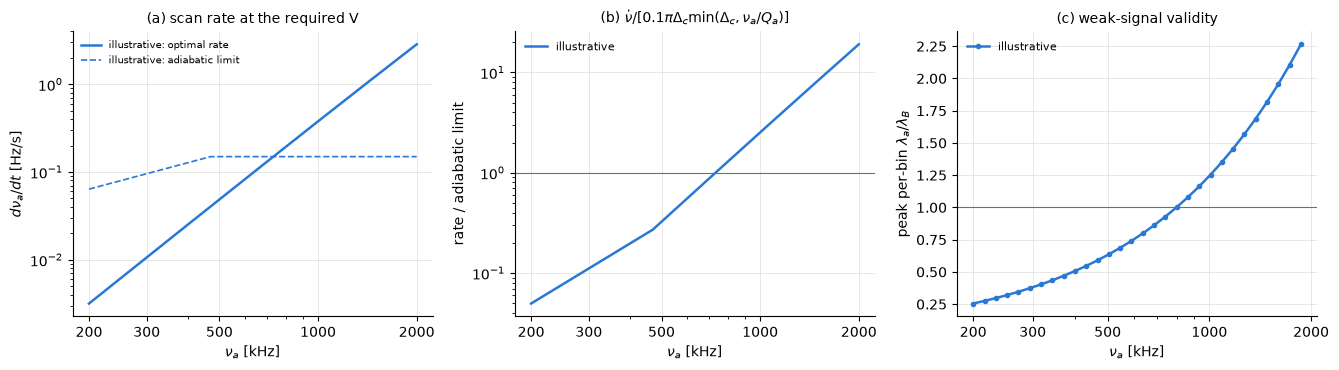

In [15]:
target = band                              # the illustrative band of the sizing above
fa = np.geomspace(target.f_min_Hz, target.f_max_Hz, 300)
fig, axs = plt.subplots(1, 3, figsize=(13.5, 3.8))
for (sname, col) in (("illustrative", BLUE),):
    sc, d = designs[sname, "this solve, B_pk wall"]
    g, V = sc.geometry, d["V_m3"]
    f1 = d["f0_Hz"] + fa
    Qi = g.G_signal_ohm / sc.Rs(f1)
    n_i = het.occupation(f1, sc.T_K)
    beta = het.beta_opt(sc.A, n_i)
    rate = het.scan_rate(fa, f1, V, sc.B0_T, g.eta, Qi, sc.A, n_i, beta=beta, target=target)
    track = het.tracking_rate(beta, fa, f1, Qi, 0.1)
    snr = het.peak_bin_snr(sc, V, fa[::10], target=target)
    t_cum = np.concatenate([[0], np.cumsum(np.diff(fa) / (0.5 * (rate[1:] + rate[:-1])))])
    print(f"{sname}: scan time {t_cum[-1] / het.YEAR:.3f} yr (live time {target.live_time_yr:g}); half of it below {np.interp(0.5, t_cum / t_cum[-1], fa) / 1e3:.0f} kHz; "
          f"rate {rate[0]:.3g} -> {rate[-1]:.3g} Hz/s; rate/tracking limit at the band ends "
          f"{d['adiabatic_ratio_ends'][0]:.3f} / {d['adiabatic_ratio_ends'][1]:.2f}; condition violated above "
          f"{d['adiabatic_violated_above_Hz'] / 1e3:.0f} kHz")
    axs[0].loglog(fa / 1e3, rate, color=col, label=f"{sname}: optimal rate")
    axs[0].loglog(fa / 1e3, track, color=col, ls="--", lw=1.2, label=f"{sname}: adiabatic limit")
    axs[1].loglog(fa / 1e3, rate / track, color=col, label=sname)
    axs[2].semilogx(fa[::10] / 1e3, snr, "o-", ms=3, color=col, label=sname)
axs[0].set_ylabel(r"$d\nu_a/dt$ [Hz/s]"); axs[0].set_title("(a) scan rate at the required V", fontsize=10)
axs[0].legend(fontsize=7)
axs[1].axhline(1, color=GREY, lw=0.8); axs[1].set_ylabel("rate / adiabatic limit")
axs[1].set_title(r"(b) $\dot\nu/[0.1\pi\Delta_c\min(\Delta_c,\nu_a/Q_a)]$", fontsize=10); axs[1].legend(fontsize=8)
axs[2].axhline(1, color=GREY, lw=0.8); axs[2].set_ylabel(r"peak per-bin $\lambda_a/\lambda_B$")
axs[2].set_title("(c) weak-signal validity", fontsize=10); axs[2].legend(fontsize=8)
from matplotlib.ticker import NullFormatter
for ax in axs:
    ax.set_xlabel(r"$\nu_a$ [kHz]"); ax.set_xscale("log")
    ax.set_xticks([200, 300, 500, 1000, 2000], ["200", "300", "500", "1000", "2000"]); ax.xaxis.set_minor_formatter(NullFormatter())
fig.tight_layout(); plt.show()

for sname in SCEN:
    sc, d = designs[sname, "this solve, B_pk wall"]
    Vad = het.required_volume(sc, band, adiabatic_eps=0.1)
    print(f"{sname}: with the adiabatic schedule (beta raised where the condition binds) V = {Vad:.1f} m^3 "
          f"({100 * rel(Vad, d['V_m3']):+.2f} %)")

Ratios above unity exceed tracking. Exact statistics and tracking are imposed separately here; `adiabatic_eps=0.1` should be combined with `het.required_volume_exact` when both matter. `guard_Hz` provides endpoint coverage; these scans are unguarded.


## Vibration requirement

Wall motion at the splitting frequency can scatter pump energy into the signal mode. The displacement amplitude spectral density must obey

$$
S_u^{1/2}\leq\frac{2\sqrt{2}\,L_c}{\eta_{\rm mix}}
\left(\frac{\epsilon n_i\hbar}{U_0 Q_i}\right)^{1/2}.
$$

Here $\eta_{\rm mix}$ measures dimensionless mode mixing, $L_c=V^{1/3}$, $U_0=B_0^2V/(2\mu_0)$ and $Q_i=G_{\rm signal}/R_s$; $Q_i$ is intrinsic signal quality factor and $R_s$ surface resistance. $n_i$ is thermal occupation at the pump frequency and wall temperature; $\epsilon$ is the tolerated noise fraction. The cell assumes unit mixing and a 0.1 noise fraction. Output is a bound in metres per square-root hertz, not a mechanical spectrum; smaller mixing relaxes it. Ideal axisymmetric TM/TE modes have zero first-order mixing; static asymmetry enables it.

We evaluate the bound for the illustrative scenario to quantify the vibration requirement.


In [16]:
# Displacement-noise requirement at eta_mix = 1, eps = 0.1:
#   S_u^(1/2) <= (2 sqrt2 L_c / eta_mix) (eps n_i hbar / (U0 Q_i))^(1/2),  L_c = V^(1/3), n_i at f0
from axionfem.circuit import HBAR
for sname in SCEN:
    sc, d = designs[sname, "this solve, B_pk wall"]
    n_i = float(het.occupation(d["f0_Hz"], sc.T_K))
    Qi = sc.geometry.G_signal_ohm / sc.Rs(d["f0_Hz"])
    Su = 2 * math.sqrt(2) * d["V_m3"] ** (1 / 3) * math.sqrt(0.1 * n_i * HBAR / (d["U0_J"] * Qi))
    print(f"{sname}: S_u^1/2 <= {Su:.2e} m/sqrt(Hz) at eta_mix = 1")

illustrative: S_u^1/2 <= 9.27e-24 m/sqrt(Hz) at eta_mix = 1
